# Parametric variograms for empirical surface maps
Here we address reviewer comment regarding whether interpolating with the best fitted variogram to empirical data works better. \
**Data:** 24 surface maps from Neuromaps, registered to the fsLR-4k midthickness mesh excluding medial wall.

In [1]:
from config import *
from figs_config import *
from interpmodules import helpers, metrics
import numpy as np

Loaded aesthetics module


In [2]:
import joblib
import pandas as pd
import pyvista as pv

src_pvdata = joblib.load( projdir + '/data/fsLR-4k_reduced-midthickness_neuromaps.pkl')

In [3]:
Dist = helpers.internal_distance_matrix(src_pvdata.points, 'euclidean')

In [4]:
import joblib
mapnames, h, all_ev = joblib.load( '/home/yzhou/gitrepo/interpolate/results/stats/neuromaps_collected_expvgm.pkl' )

In [5]:
def clean_variogram(h, ev, nooutlier=True):

    outliers = np.array([], dtype=bool)
    nans = np.where( np.isnan(ev) )

    if nooutlier: outliers = np.where( abs(ev) > np.nanstd(ev)*5 )
    remove = np.union1d( outliers, nans )

    ev_clean = np.delete(ev, remove)
    h_clean = np.delete(h, remove)

    return h_clean, ev_clean

def get_neuromaps_palette():
    
    extended_cpal = {}
    
    global_i_s = pd.DataFrame(index = mapnames, columns = ['i'])
    
    for mapname in mapnames:
        global_i = helpers.morans_i(Dist, src_pvdata[mapname], normalize=True)
        global_i_s.loc[mapname] = global_i
    
    maptocat = {'gene expression': ['abagen_genepc1'], \
                'MEG': ['hcps1200_meg' + fband for fband in fbands ] + ['hcps1200_megtimescale'], \
                'structural': ['hcps1200_thickness', 'hcps1200_myelinmap'], \
                'functional': ['margulies2016_fcgradient01', 'mueller2013_intersubjvar', 'xu2020_FChomology', 'sydnor2021_SAaxis'], \
                'metabolism': ['raichle_cbf', 'raichle_cbv', 'raichle_cmr02', 'raichle_cmrglc'], \
                'expansion': ['hill2010_devexp', 'hill2010_evoexp', 'xu2020_evoexp', 'reardon2018_scalinghcp', 'reardon2018_scalingnih', 'reardon2018_scalingpnc']}
    
    cat = []
    for row in range(len(global_i_s)):
        for category in maptocat:
            if global_i_s.index[row] in maptocat[category]:
                cat.append(category)
            else: continue
    
    global_i_s['category'] = cat
    
    for mapname in mapnames:
        extended_cpal[mapname] = cpal[global_i_s.loc[mapname]['category']]
        
    return extended_cpal
    
def init_parameters(mapvals, Dist, h, ev):

    nh = len(h)
    max_ev = semivariance(np.nanmax(mapvals), np.nanmin(mapvals))
    p0 = {
          3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
          4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
         }
    # upper bound lower bound
    bounds = {
        3: ([0.00001]*3,
        [np.max(Dist), max_ev, max_ev]),
        4: ([0.00001]*4, 
        [np.max(Dist), max_ev, max_ev, 100])
    }

    return p0, bounds

def semivariance(y1, y2):
    return .5 * (y1 - y2)**2

## Fitting variogram models to whole samples
We explore parametric isotropic models ([Ref](https://scikit-gstat.readthedocs.io/en/latest/reference/models.html)) using the implementation in GSTools and directly paste the GSTools variogram model to perform 3D kriging using PyKrige. \
**N.B.** The range parameter in the original formulae are rescaled using the `convert_to_length` helper function from `interpmodules.helpers` to satisfy the requirements of the GSTools implementation of the variogram/correlogram models. Rescaling uses a scaling factor that is different for each model.

In [6]:
# get colour palette
extended_cpal = get_neuromaps_palette()

In [7]:
import gstools as gs

MODELS = {'spherical': gs.covmodel.Spherical, 
                'exponential': gs.covmodel.Exponential,
                'gaussian': gs.covmodel.Gaussian,
                'cubic': gs.covmodel.Cubic,
                'stable': gs.covmodel.Stable,
                'matern': gs.covmodel.Matern,
               'hole': gs.covmodel.JBessel}

## Fitting variogram models to sparse sample
We load an even sample of 5% of the mesh, with which we fit different variogram models.

In [8]:
pct=5
sampl = joblib.load(projdir + f'/data/sampling/fsLR-4k_reduced-midthickness_samp-fibonacci_pct-{str(pct)}.pkl')[1]
kc, kv, uc, uv = sampl
train_coords = kc[:,:,0]
test_coords = uc[:, :, 0]

In [9]:
print("known sample size: " + str(train_coords.shape[0]))
print("unknown sample size:" + str(test_coords.shape[0]))

known sample size: 179
unknown sample size:3420


We show the values at known locations

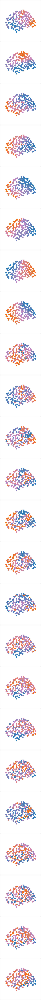

In [10]:
# show sampling
pl = pv.Plotter(shape = (len(mapnames), 1), window_size = (400, len(mapnames)*400))

for mi, mapname in enumerate(mapnames):
    pl.subplot(mi, 0)
    mapvals = src_pvdata[mapname]
    train_data = mapvals[kv[:, 0].astype(int)]
    pl.add_points(pv.PolyData(train_coords).rotate_z(180),
                  scalars = train_data,
                  clim = (np.percentile(src_pvdata[mapname], 5), np.percentile(src_pvdata[mapname], 95)),
                  cmap = bpr, point_size = 15, show_scalar_bar=False, **point_aes)
    #pl.add_mesh(src_pvdata.rotate_z(180), color="lightgray", opacity = 0.5, **mesh_aes)
    pl.camera_position='yz'

pl.show(jupyter_backend='static')
pl.save_graphic(projdir + f"/figs/rev_example_neuromaps_sampling_{pct}pct.svg")

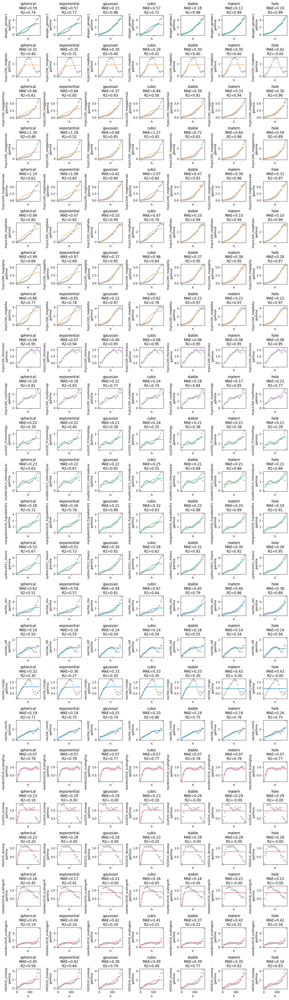

In [13]:
from scipy.stats import zscore
from sklearn.metrics import r2_score

fig, axs = plt.subplots(len(mapnames), len(MODELS), figsize = (len(MODELS)*2, len(mapnames)*2), sharex=True)
Cof = dict.fromkeys(mapnames); Cov = dict.fromkeys(mapnames); gof = dict.fromkeys(mapnames)

for mi, mapname in enumerate(mapnames):
    mapvals = zscore(src_pvdata[mapname])
    train_data = mapvals[kv[:, 0].astype(int)]
    test_data = mapvals[uv[:, 0].astype(int)]
    Cof[mapname] = dict.fromkeys(MODELS.keys())
    Cov[mapname] = dict.fromkeys(MODELS.keys())
    gof[mapname] = dict.fromkeys(MODELS.keys())
    
    h, ev, N = helpers.get_empirical_variogram_fast(x=train_data,
                                                X=train_coords,
                                                D=Dist,
                                                nh=25,
                                                h_bounds='auto',
                                                method='euclidean')
    h_clean, ev_clean = clean_variogram(h, ev, False)

    for ind, mod in enumerate(MODELS):
    
        cof = None; cov = None
    
        axs[mi, ind].scatter(h_clean, ev_clean, marker = "+", color = 'darkgrey')
        
        p0, bounds = init_parameters(mapvals, Dist, h, ev)
        h_clean, ev_clean = clean_variogram(h, ev, False)
        mdl = MODELS[mod](dim=3)
        
        if mod in ['stable', 'matern']:
            in_bounds = {"len_scale": [bounds[4][0][0], bounds[4][1][0]],\
                     "var": [bounds[4][0][1], bounds[4][1][1]],\
                     "nugget": [bounds[4][0][2], bounds[4][1][2]],\
                     "smoothness": [bounds[4][0][3], bounds[4][1][3]]
                    }
            if mod == 'stable':
                in_bounds["alpha"] = [bounds[4][0][3], 2] # upper bound for alpha shape parameter set to 2 to satisfy PyKrige
                del in_bounds["smoothness"]
                mdl.set_arg_bounds(**in_bounds)
                cof, cov = mdl.fit_variogram(h,ev, init_guess = {"len_scale": p0[4][0], "var": p0[4][1], "nugget": p0[4][2], "alpha": p0[4][3]}, 
                                             max_eval = 1000)
                
            if mod == 'matern':
                in_bounds["nu"] = [0.2, 20] # upper bound for nu shape parameter set to 20 to satisfy PyKrige
                del in_bounds["smoothness"]
                mdl.set_arg_bounds(**in_bounds)
                cof, cov = mdl.fit_variogram(h_clean, ev_clean, init_guess = {"len_scale": p0[4][0], "var": p0[4][1], "nugget": p0[4][2], "nu": p0[4][3]}, 
                                             max_eval = 1000)
        else:
            in_bounds = {"len_scale": [bounds[3][0][0], bounds[3][1][0]],\
                     "var": [bounds[3][0][1], bounds[3][1][1]],\
                     "nugget": [bounds[3][0][2], bounds[3][1][2]]
                    }
            
            mdl.set_arg_bounds(**in_bounds)
            cof, cov = mdl.fit_variogram(h_clean ,ev_clean, init_guess = {"len_scale": p0[3][0], "var": p0[3][1], "nugget": p0[3][2]}, 
                                         max_eval = 1000)
    
        Cof[mapname][mod] = cof
        Cov[mapname][mod] = cov
        
        v_pred = mdl.variogram(h_clean)
        axs[mi, ind].plot(h_clean, v_pred, color = extended_cpal[mapname])
        
        mae = np.mean(metrics.metric(v_pred, ev_clean, 'residual'))
        r2 = r2_score(ev_clean, v_pred, force_finite=False)
        gof[mapname][mod] = r2
    
        axs[mi, ind].set_xlabel("h")
        axs[mi, ind].set_ylabel(f"{mapname} \n gamma")
        axs[mi, ind].set_title(mod + 
                           "\n" + 
                           f'MAE={mae:.2f}' +
                           "\n" +
                          f'R2={r2:.2f}')
plt.tight_layout()
plt.show()

In [14]:
fitscores = pd.DataFrame.from_dict(gof).T

### Evaluating the fitted variogram models
We describe the goodness of fit of each variogram model to empirical map via R2

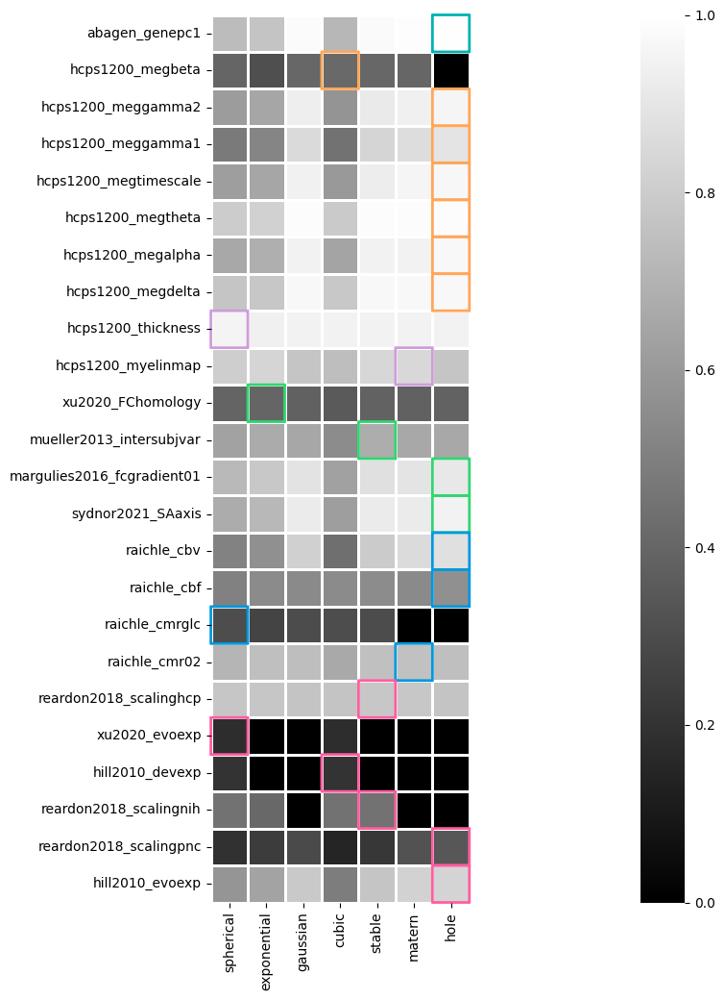

In [16]:
from matplotlib.patches import FancyBboxPatch
import seaborn as sns

fig, ax = plt.subplots(figsize = (len(mapnames)*1.5, len(MODELS)*1.5))
sns.heatmap(
    fitscores,
    vmin=0,
    vmax=1,
    square=True,
    cmap="gist_yarg_r",
    linewidth=1,
    linecolor='w',
    fmt=".2f",
    ax=ax
)

row_labels = []

data = fitscores
for mapname in mapnames:
    col_label = mapname
    row_label = data.loc[mapname].sort_values(ascending = False).index[0]
    row_labels.append(row_label)

    i = data.columns.get_loc(row_label)
    j = data.index.get_loc(col_label)
    
    ax.add_patch(
        FancyBboxPatch(
            (i, j), 1, 1,
            boxstyle="round,pad=0.0001",
            linewidth=2,
            edgecolor=extended_cpal[mapname],
            facecolor="none", clip_on=False
        ))
    
plt.tight_layout()
plt.savefig(projdir + "/figs/rev_other_kriging_best_fitted_r2.svg")

In [17]:
from pykrige.ok3d import OrdinaryKriging3D

preds = dict.fromkeys(mapnames)

for mi, mapname in enumerate(mapnames):
    preds[mapname] = dict.fromkeys(MODELS)
    mapvals = zscore(src_pvdata[mapname])
    train_data = mapvals[kv[:, 0].astype(int)]
    test_data = mapvals[uv[:, 0].astype(int)]
    for ind, mod in enumerate(MODELS):
        fitted = MODELS[mod](dim=3, **Cof[mapname][mod])
    
        kriger = OrdinaryKriging3D(
            x=train_coords[:, 0],
            y=train_coords[:,1],
            z=train_coords[:,2],
            val = train_data,
            variogram_model = fitted,
            exact_values = True)
        y1, error = kriger.execute(style = 'points',
                                   xpoints = test_coords[:, 0],
                                   ypoints = test_coords[:, 1],
                                   zpoints = test_coords[:, 2])
        full = np.zeros(src_pvdata.n_points)
        full[kv[:,0].astype(int)] = train_data
        full[uv[:,0].astype(int)] = y1
    
        preds[mapname][mod] = full
        
joblib.dump(preds, projdir + f"/results/rev_example_neuromaps_krige_{pct}pct.pkl")

/home/yzhou/anaconda3/envs/py311/lib/python3.11/site-packages/gstools/covmodel/models.py:999: AttributeWarning: JBessel: parameter 'nu' is close to d/2-1, count with unstable results
  warnings.warn(
/home/yzhou/anaconda3/envs/py311/lib/python3.11/site-packages/gstools/covmodel/models.py:338: AttributeWarning: Stable: parameter 'alpha' is < 0.3, count with unstable results
  warnings.warn(


['..//results/rev_example_neuromaps_krige_5pct.pkl']

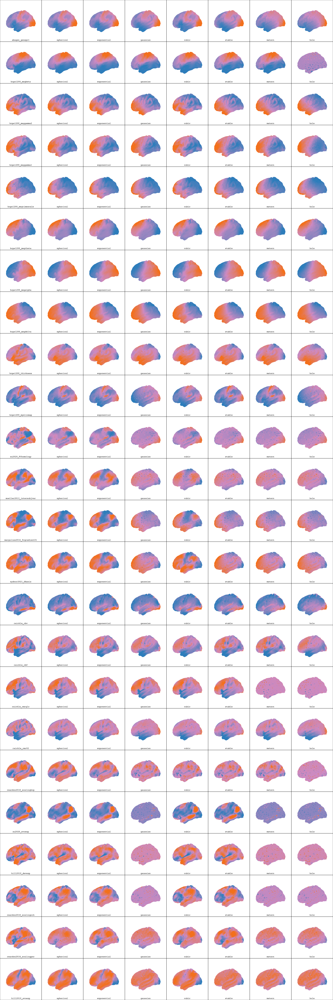

In [39]:
import pyvista as pv

pl = pv.Plotter(shape = (len(mapnames),len(MODELS) + 1), window_size = ((len(MODELS) + 1)*400, (len(mapnames))*400))

for mi, mapname in enumerate(mapnames):
    pl.subplot(mi, 0)
    pl.add_mesh(
        src_pvdata.rotate_z(180),
        scalars=mapname,
        clim = (np.percentile(src_pvdata[mapname], 5), np.percentile(src_pvdata[mapname], 95)),
        cmap = bpr,
        **mesh_aes)
    pl.add_text(mapname, position = "lower_edge", font = "courier", font_size = 8)
    pl.camera_position = "yz"

    for ind, mod in enumerate(MODELS):
    
        pl.subplot(mi, ind + 1)
        pl.add_mesh(
            src_pvdata.rotate_z(180),
            scalars=preds[mapname][mod],
            clim = (np.percentile(zscore(src_pvdata[mapname]), 5), np.percentile(zscore(src_pvdata[mapname]), 95)),
            cmap = bpr,
            **mesh_aes)
        pl.add_text(mod, position="lower_edge", font = 'courier', font_size = 8)
        pl.camera_position='yz'
    
pl.show(jupyter_backend='static')
pl.save_graphic(projdir + "/figs/rev_neuromaps_krige.svg")

## Evaluating the different models
Opting for NRMSE to compare interpolated data to ground truth data at unknown locations.

In [54]:
scores = np.ones((len(mapnames), len(MODELS)))
for mi, mapname in enumerate(mapnames):
    for ind, mod in enumerate(MODELS.keys()):
        mapvals = zscore(src_pvdata[mapname])
        y_true = mapvals[uv[:,0].astype(int)]
        y_pred = preds[mapname][mod][uv[:,0].astype(int)]
        rmse = metrics.metric(actual=y_true, interpolated=y_pred, method="rmse")
        nrmse = rmse/np.std(y_true)
        scores[mi, ind] = nrmse

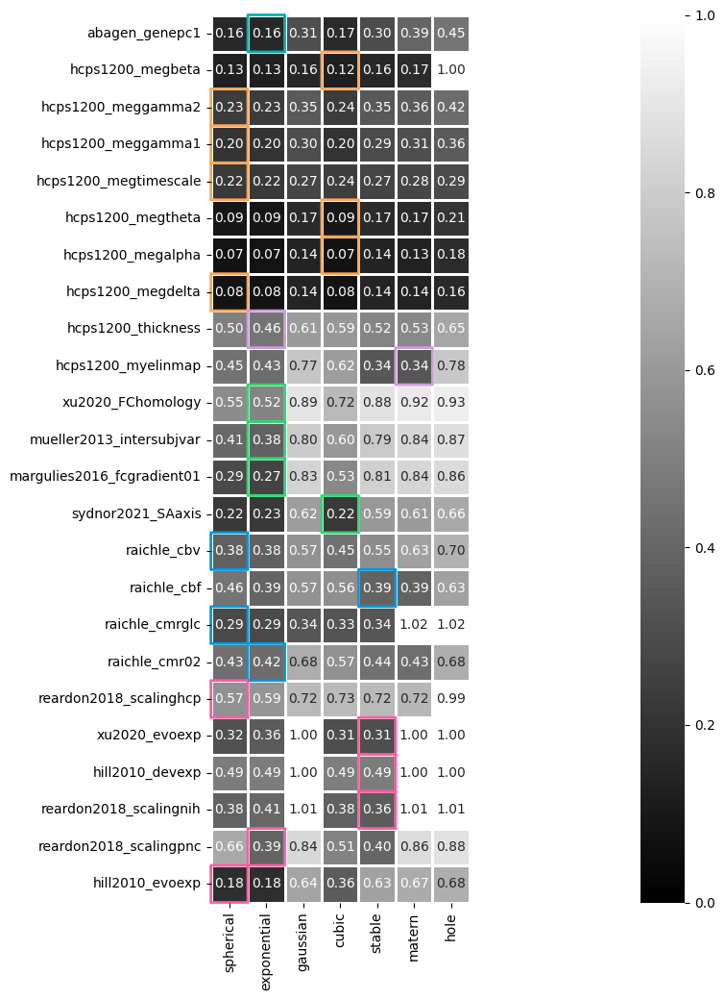

In [55]:
from matplotlib.patches import FancyBboxPatch
import seaborn as sns

fig, ax = plt.subplots(figsize = (len(mapnames)*1.5, len(MODELS)*1.5))
sns.heatmap(
    scores,
    annot=scores,
    vmin=0,
    vmax=1,
    yticklabels=mapnames,
    xticklabels=MODELS.keys(),
    square=True,
    cmap="gist_yarg_r",
    linewidth=1,
    linecolor='w',
    fmt=".2f",
    ax=ax
)

row_labels = []

data = pd.DataFrame(scores, columns = MODELS.keys(), index = mapnames)
for mapname in mapnames:
    col_label = mapname
    row_label = data.loc[mapname].sort_values(ascending = True).index[0]
    row_labels.append(row_label)

    i = data.columns.get_loc(row_label)
    j = data.index.get_loc(col_label)
    
    ax.add_patch(
        FancyBboxPatch(
            (i, j), 1, 1,
            boxstyle="round,pad=0.0001",
            linewidth=2,
            edgecolor=extended_cpal[mapname],
            facecolor="none", clip_on=False
        ))
    
plt.tight_layout()
plt.savefig(projdir + "/figs/rev_other_kriging_best_nrmse.svg")